# Perbandingan Multi-Layer Perceptron dan Convolutional Neural Network untuk Pemilahan Sampah Rumah Tangga Otomatis Berbasis Citra

**Dataset:** [Garbage Classification (Kaggle)](https://www.kaggle.com/datasets/mostafaabla/garbage-classification) · 12 kelas

**Kelompok:**
1. Steven Raffael Antonius Sidauruk (231112060)
2. William Patar Wijaya Marpaung (231112393)
3. Arisanti Nurlaili (231112294)
4. Maria Hana Gultom (231112124)
5. Muhammad Aswan Tagiy (231112002)
6. Daniel Pangihutan Siregar (231112256)

| Bagian | Kriteria Penilaian | Bobot | PIC |
|---|---|---|---|
| 1 | Kompleksitas masalah dan dataset | 15% | Steven |
| 2 | Preprocessing data | 15% | William |
| 3 | Arsitektur model dan justifikasi desain | 25% | Arisanti (MLP, eksperimen) · Maria (CNN, Transfer Learning) |
| 4 | Akurasi/error dan analisis hasil | 15% | Daniel |
| 5 | Teknologi, deployment, dan demo | 15% | Aswan |
| 6 | Kualitas laporan dan dokumentasi | 15% | Steven (kompilasi) · semua anggota |

# SETUP — Library, Konstanta, dan Seed

In [ ]:
!pip -q install kagglehub

In [ ]:
import os, json, time, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, precision_score, recall_score)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

os.makedirs("assets", exist_ok=True)
os.makedirs("models", exist_ok=True)

def save_fig(name):
    plt.savefig(f"assets/{name}.png", dpi=150, bbox_inches="tight")

print("TensorFlow :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# BAGIAN 1 — Kompleksitas Masalah dan Dataset
Bagian: Steven

### 1.1 Memuat Dataset

In [ ]:
import kagglehub
raw_path = kagglehub.dataset_download("mostafaabla/garbage-classification")

EXT = (".jpg", ".jpeg", ".png")

def find_root(base):
    for r, dirs, _ in os.walk(base):
        if len(dirs) >= 12:
            ok = all(any(f.lower().endswith(EXT) for f in os.listdir(os.path.join(r, d))) for d in dirs)
            if ok:
                return r
    raise FileNotFoundError("Folder kelas tidak ditemukan")

DATA_DIR = find_root(raw_path)
CLASS_NAMES = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
NUM_CLASSES = len(CLASS_NAMES)

rows = [(os.path.join(DATA_DIR, c, f), c)
        for c in CLASS_NAMES for f in os.listdir(os.path.join(DATA_DIR, c))
        if f.lower().endswith(EXT)]
df = pd.DataFrame(rows, columns=["path", "class"])

print("Lokasi data :", DATA_DIR)
print("Jumlah kelas:", NUM_CLASSES, CLASS_NAMES)
print("Jumlah citra:", len(df))

100%|██████████| 239M/239M [00:02<00:00, 99.0MB/s]

Extracting files...


Lokasi data : /root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification
Jumlah kelas: 12 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Jumlah citra: 15515


### 1.2 Distribusi Kelas

,jumlah
class,
battery,945
biological,985
brown-glass,607
cardboard,891
clothes,5325
green-glass,629
metal,769
paper,1050
plastic,865


Rasio imbalance (max/min): 8.77


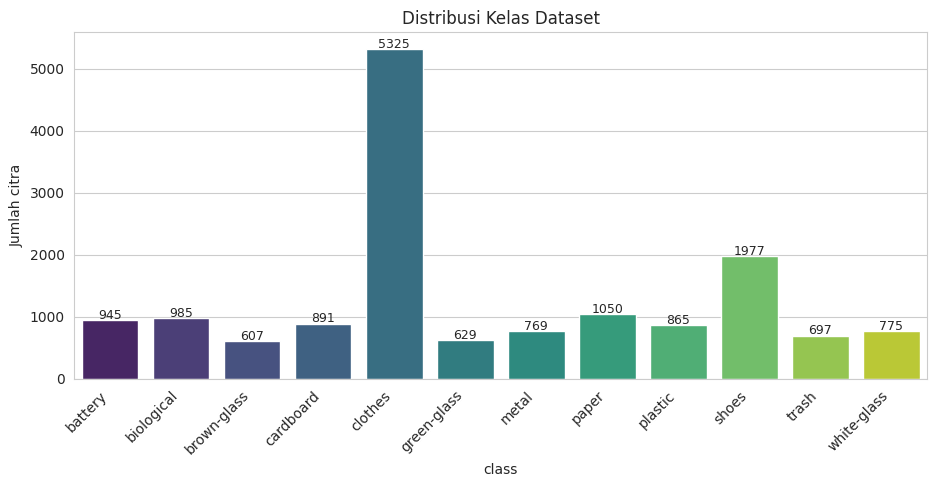

In [ ]:
counts = df["class"].value_counts().sort_index()
display(counts.to_frame("jumlah"))
print("Rasio imbalance (max/min): %.2f" % (counts.max() / counts.min()))

plt.figure(figsize=(11, 4.5))
ax = sns.barplot(x=counts.index, y=counts.values, palette="viridis")
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, str(v), ha="center", fontsize=9)
plt.xticks(rotation=45, ha="right"); plt.ylabel("Jumlah citra"); plt.title("Distribusi Kelas Dataset")
save_fig("01_distribusi_kelas"); plt.show()

### 1.3 Contoh Citra per Kelas

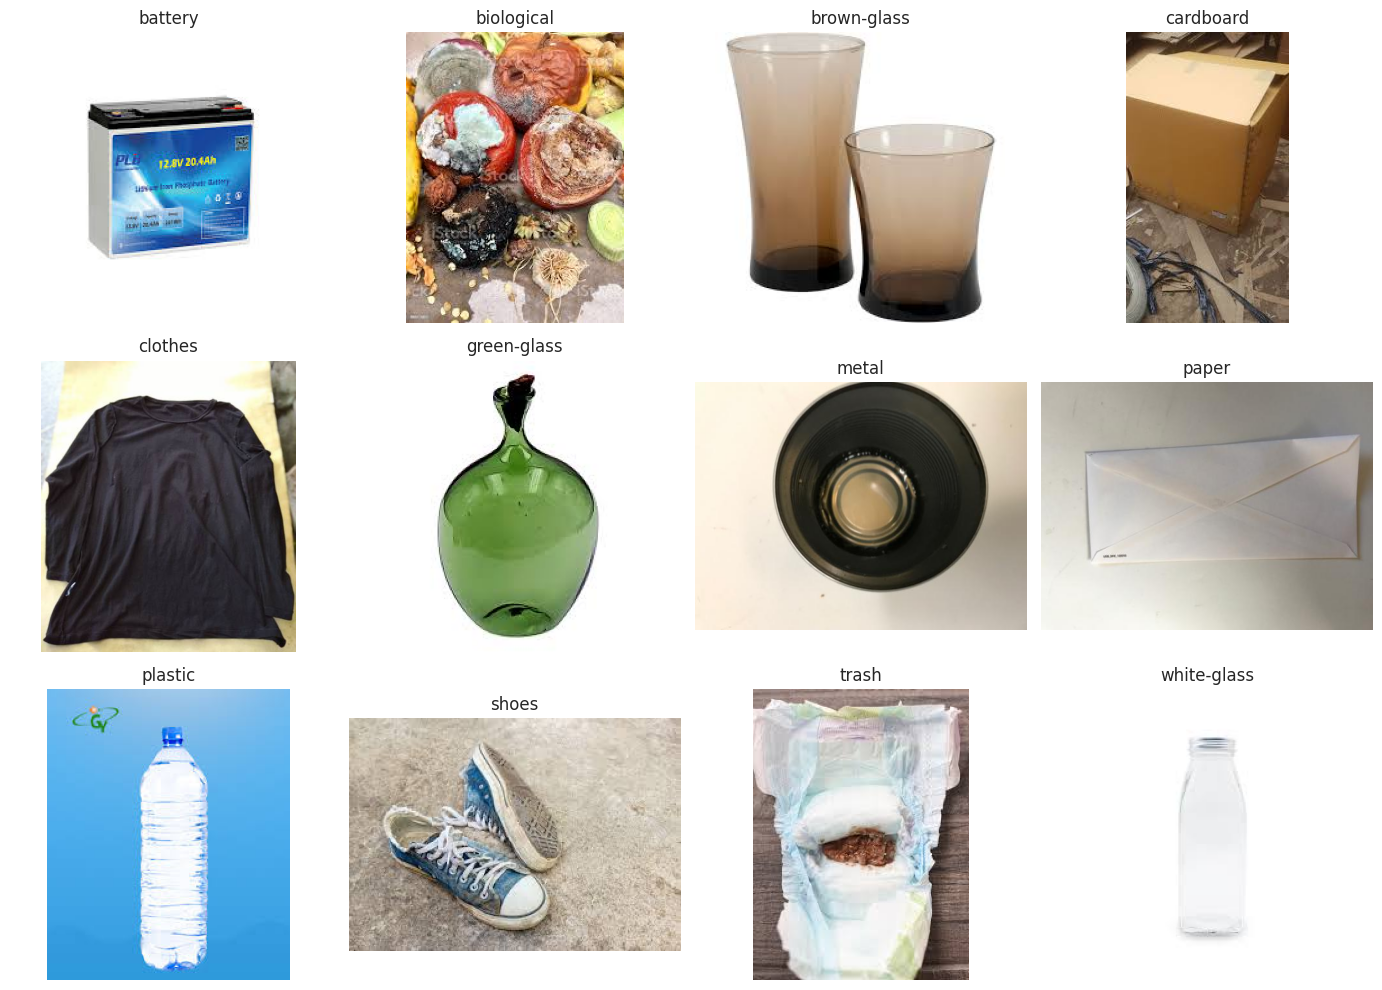

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, c in zip(axes.ravel(), CLASS_NAMES):
    p = df[df["class"] == c].sample(1, random_state=SEED).path.iloc[0]
    with Image.open(p) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(c); ax.axis("off")
plt.tight_layout(); save_fig("02_contoh_citra"); plt.show()

### 1.4 Variasi Resolusi Citra

In [ ]:
def get_size(p):
    with Image.open(p) as im:
        return im.size

sample = df.sample(min(500, len(df)), random_state=SEED)
sz = pd.DataFrame([get_size(p) for p in sample.path], columns=["width", "height"])
display(sz.describe().round(1))
print("Jumlah ukuran unik pada sampel:", sz.drop_duplicates().shape[0])

,width,height
count,500.0,500.0
mean,360.6,350.7
std,122.5,143.7
min,110.0,147.0
25%,252.0,224.0
50%,400.0,384.0
75%,409.0,532.2
max,865.0,712.0


Jumlah ukuran unik pada sampel: 124


# BAGIAN 2 — Preprocessing Data
Bagian William

### 2.1 Pembersihan: Citra Rusak

In [ ]:
def is_ok(p):
    try:
        with Image.open(p) as im:
            im.verify()
        return True
    except Exception:
        return False

df["ok"] = df["path"].map(is_ok)
print("Citra rusak:", int((~df["ok"]).sum()))
df = df[df["ok"]].drop(columns="ok").reset_index(drop=True)
print("Sisa citra :", len(df))

Citra rusak: 0
Sisa citra : 15515


### 2.2 Pembersihan: Citra Duplikat

In [ ]:
def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df["path"].map(md5)
n_before = len(df)
df = df.drop_duplicates(subset="hash").drop(columns="hash").reset_index(drop=True)
print("Duplikat dibuang:", n_before - len(df))
print("Sisa citra      :", len(df))

Duplikat dibuang: 19
Sisa citra      : 15496


### 2.3 Label Encoding dan Split Train / Validation / Test (70/15/15, stratified)

Train: 10847 | Val: 2324 | Test: 2325


,train,val,test
class,,,
battery,661,142,142
biological,689,148,148
brown-glass,425,91,91
cardboard,624,133,134
clothes,3727,798,799
green-glass,430,92,92
metal,538,116,115
paper,735,157,158
plastic,606,130,129


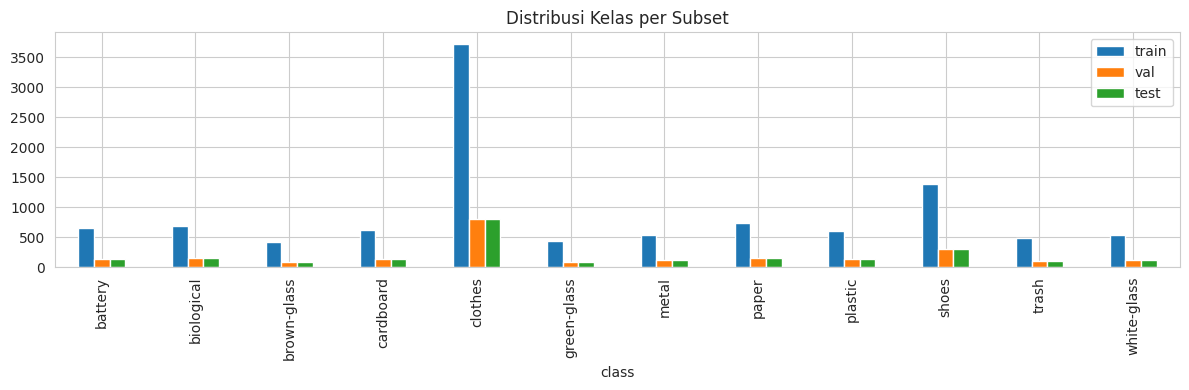

In [ ]:
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
df["label"] = df["class"].map(class_to_idx)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

split_cnt = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "val": val_df["class"].value_counts(),
    "test": test_df["class"].value_counts()}).loc[CLASS_NAMES]
display(split_cnt)
split_cnt.plot(kind="bar", figsize=(12, 4), title="Distribusi Kelas per Subset")
plt.tight_layout(); save_fig("03_distribusi_split"); plt.show()

### 2.4 Pipeline Data (Resize 224x224, Batching, Prefetch)

In [ ]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_ds(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label"].values.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

### 2.5 Data Augmentation (hanya aktif saat training)

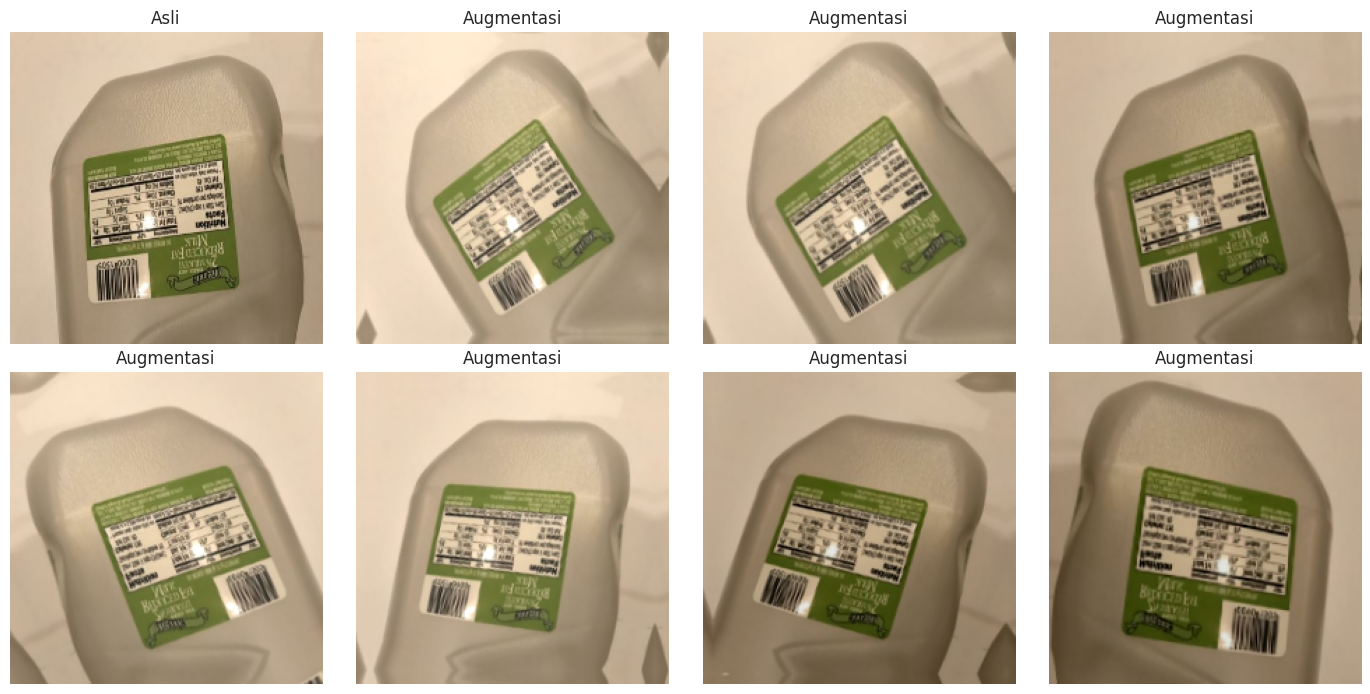

In [ ]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="augmentation")

imgs, _ = next(iter(train_ds.take(1)))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(imgs[0].numpy().astype("uint8")); axes[0, 0].set_title("Asli"); axes[0, 0].axis("off")
for ax in axes.ravel()[1:]:
    aug = augment(tf.expand_dims(imgs[0], 0), training=True)[0]
    ax.imshow(np.clip(aug.numpy(), 0, 255).astype("uint8")); ax.set_title("Augmentasi"); ax.axis("off")
plt.tight_layout(); save_fig("04_augmentasi"); plt.show()

### 2.6 Penanganan Imbalance (Class Weight)

In [ ]:
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw)}
display(pd.DataFrame({"kelas": CLASS_NAMES, "weight": [round(CLASS_WEIGHTS[i], 3) for i in range(NUM_CLASSES)]}))

,kelas,weight
0,battery,1.367
1,biological,1.312
2,brown-glass,2.127
3,cardboard,1.449
4,clothes,0.243
5,green-glass,2.102
6,metal,1.680
7,paper,1.230
8,plastic,1.492
9,shoes,0.653


# BAGIAN 3 — Arsitektur Model dan Justifikasi Desain
Bagian: Arisanti (3.1, 3.4) dan Maria (3.2, 3.3)

### 3.0 Fungsi Bantu Training (kompilasi, callback, pencatatan waktu)

In [ ]:
HIST, TRAIN_TIME = {}, {}
KEYS = ["loss", "accuracy", "val_loss", "val_accuracy"]

def get_optimizer(name, lr):
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=lr)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    raise ValueError(name)

def compile_model(model, opt="adam", lr=1e-3):
    model.compile(optimizer=get_optimizer(opt, lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def fit_model(model, epochs, verbose=1):
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7)]
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                  class_weight=CLASS_WEIGHTS, callbacks=cbs, verbose=verbose)
    return h, time.time() - t0

### 3.1 Model A — MLP (Baseline) Arisanti

In [ ]:
def build_mlp(dropout=0.4):
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Resizing(64, 64)(x)
    x = layers.Rescaling(1. / 255)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="MLP_baseline")

mlp = build_mlp()
mlp.summary()

Model: "MLP_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 12)             │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,429,452 (24.53 MB)

 Trainable params: 6,427,916 (24.52 MB)

 Non-trainable params: 1,536 (6.00 KB)

### 3.2 Model B — CNN dari Nol  ·  Maria

In [ ]:
def build_cnn(dropout=0.5):
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1. / 255)(x)
    for f in (32, 64, 128, 256):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="CNN_scratch")

cnn = build_cnn()
cnn.summary()

Model: "CNN_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 458,732 (1.75 MB)

 Trainable params: 457,772 (1.75 MB)

 Non-trainable params: 960 (3.75 KB)

### 3.3 Model C — CNN Transfer Learning (MobileNetV2)  ·  Maria

In [ ]:
def build_transfer(dropout=0.3):
    base = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1. / 127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="MobileNetV2_TL"), base

_tmp, _ = build_transfer()
_tmp.summary()
del _tmp

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,356 (8.67 MB)

 Trainable params: 15,372 (60.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 3.4 Eksperimen Hyperparameter (optimizer, learning rate, dropout)  ·  Arisanti

In [ ]:
EXPERIMENTS = [("adam", 1e-3, 0.3), ("adam", 1e-4, 0.3), ("sgd", 1e-2, 0.3), ("adam", 1e-3, 0.5)]
exp_rows = []
for opt, lr, dr in EXPERIMENTS:
    m, _ = build_transfer(dropout=dr)
    compile_model(m, opt, lr)
    h = m.fit(train_ds, validation_data=val_ds, epochs=3, class_weight=CLASS_WEIGHTS, verbose=0)
    exp_rows.append({"optimizer": opt, "learning_rate": lr, "dropout": dr,
                     "best_val_acc": round(max(h.history["val_accuracy"]), 4),
                     "best_val_loss": round(min(h.history["val_loss"]), 4)})
    print(exp_rows[-1])

exp_df = pd.DataFrame(exp_rows).sort_values("best_val_acc", ascending=False).reset_index(drop=True)
display(exp_df)
exp_df.to_csv("assets/eksperimen_hyperparameter.csv", index=False)

BEST_OPT, BEST_LR, BEST_DROPOUT = exp_df.loc[0, ["optimizer", "learning_rate", "dropout"]]
print("Konfigurasi terpilih:", BEST_OPT, BEST_LR, BEST_DROPOUT)

{'optimizer': 'adam', 'learning_rate': 0.001, 'dropout': 0.3, 'best_val_acc': 0.9342, 'best_val_loss': 0.2159}
{'optimizer': 'adam', 'learning_rate': 0.0001, 'dropout': 0.3, 'best_val_acc': 0.8752, 'best_val_loss': 0.4865}
{'optimizer': 'sgd', 'learning_rate': 0.01, 'dropout': 0.3, 'best_val_acc': 0.9436, 'best_val_loss': 0.2263}
{'optimizer': 'adam', 'learning_rate': 0.001, 'dropout': 0.5, 'best_val_acc': 0.9264, 'best_val_loss': 0.2329}


,optimizer,learning_rate,dropout,best_val_acc,best_val_loss
0,sgd,0.0100,0.3,0.9436,0.2263
1,adam,0.0010,0.3,0.9342,0.2159
2,adam,0.0010,0.5,0.9264,0.2329
3,adam,0.0001,0.3,0.8752,0.4865


Konfigurasi terpilih: sgd 0.01 0.3


### 3.5 Training Ketiga Model

In [ ]:
# Training Model A — MLP
compile_model(mlp, "adam", 1e-3)
h, t = fit_model(mlp, epochs=40)
HIST["MLP"] = {k: h.history[k] for k in KEYS}; TRAIN_TIME["MLP"] = t

Epoch 1/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - accuracy: 0.2599 - loss: 2.4327 - val_accuracy: 0.2836 - val_loss: 2.1993 - learning_rate: 0.0010
Epoch 2/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.3320 - loss: 2.0377 - val_accuracy: 0.4152 - val_loss: 2.1878 - learning_rate: 0.0010
Epoch 3/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.3640 - loss: 1.9278 - val_accuracy: 0.4376 - val_loss: 1.6678 - learning_rate: 0.0010
Epoch 4/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 48ms/step - accuracy: 0.3905 - loss: 1.8400 - val_accuracy: 0.4178 - val_loss: 1.7115 - learning_rate: 0.0010
Epoch 5/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 15s 45ms/step - accuracy: 0.3948 - loss: 1.8237 - val_accuracy: 0.3335 - val_loss: 1.9223 - learning_rate: 0.0010
Epoch 6/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.4006 - loss: 1.8068 - val_accuracy: 0.4436 - val_loss: 1.6944 - learning_rate: 0.0010
Epoch 7/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.4199 - l

In [ ]:
# Training Model B — CNN dari Nol
compile_model(cnn, "adam", 1e-3)
h, t = fit_model(cnn, epochs=40)
HIST["CNN Scratch"] = {k: h.history[k] for k in KEYS}; TRAIN_TIME["CNN Scratch"] = t

Epoch 1/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 55s 149ms/step - accuracy: 0.3790 - loss: 1.8073 - val_accuracy: 0.2453 - val_loss: 2.3013 - learning_rate: 0.0010
Epoch 2/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 80s 150ms/step - accuracy: 0.4630 - loss: 1.5749 - val_accuracy: 0.4251 - val_loss: 1.7496 - learning_rate: 0.0010
Epoch 3/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 50s 148ms/step - accuracy: 0.4915 - loss: 1.4834 - val_accuracy: 0.4811 - val_loss: 1.5153 - learning_rate: 0.0010
Epoch 4/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 48s 143ms/step - accuracy: 0.5118 - loss: 1.4237 - val_accuracy: 0.5611 - val_loss: 1.3910 - learning_rate: 0.0010
Epoch 5/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 48s 142ms/step - accuracy: 0.5279 - loss: 1.3883 - val_accuracy: 0.2151 - val_loss: 2.3426 - learning_rate: 0.0010
Epoch 6/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 51s 150ms/step - accuracy: 0.5393 - loss: 1.3310 - val_accuracy: 0.4436 - val_loss: 1.9162 - learning_rate: 0.0010
Epoch 7/40
339/339 ━━━━━━━━━━━━━━━━━━━━ 49s 145ms/step - accuracy: 0.5

In [ ]:
# Training Model C — MobileNetV2: fase 1 (feature extraction) lalu fase 2 (fine-tuning)
tl, base = build_transfer(dropout=float(BEST_DROPOUT))
compile_model(tl, BEST_OPT, float(BEST_LR))
h1, t1 = fit_model(tl, epochs=10)

base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
compile_model(tl, "adam", 1e-5)
h2, t2 = fit_model(tl, epochs=15)

HIST["MobileNetV2 (TL)"] = {k: h1.history[k] + h2.history[k] for k in KEYS}
TRAIN_TIME["MobileNetV2 (TL)"] = t1 + t2

Epoch 1/10
339/339 ━━━━━━━━━━━━━━━━━━━━ 33s 80ms/step - accuracy: 0.8370 - loss: 0.6836 - val_accuracy: 0.9208 - val_loss: 0.2761 - learning_rate: 0.0100
Epoch 2/10
339/339 ━━━━━━━━━━━━━━━━━━━━ 40s 78ms/step - accuracy: 0.8945 - loss: 0.4783 - val_accuracy: 0.9187 - val_loss: 0.2914 - learning_rate: 0.0100
Epoch 3/10
339/339 ━━━━━━━━━━━━━━━━━━━━ 26s 76ms/step - accuracy: 0.9056 - loss: 0.4101 - val_accuracy: 0.9320 - val_loss: 0.2435 - learning_rate: 0.0100
Epoch 4/10
339/339 ━━━━━━━━━━━━━━━━━━━━ 26s 77ms/step - accuracy: 0.9145 - loss: 0.3764 - val_accuracy: 0.9312 - val_loss: 0.2367 - learning_rate: 0.0100
Epoch 5/10
339/339 ━━━━━━━━━━━━━━━━━━━━ 40s 76ms/step - accuracy: 0.9149 - loss: 0.3867 - val_accuracy: 0.9286 - val_loss: 0.2538 - learning_rate: 0.0100
Epoch 6/10
339/339 ━━━━━━━━━━━━━━━━━━━━ 26s 76ms/step - accuracy: 0.9184 - loss: 0.3540 - val_accuracy: 0.9355 - val_loss: 0.2528 - learning_rate: 0.0100
Epoch 7/10
339/339 ━━━━━━━━━━━━━━━━━━━━ 25s 75ms/step - accuracy: 0.9157 - l

### 3.6 Diagram Arsitektur (untuk laporan)

In [ ]:
for name, m in {"mlp": mlp, "cnn": cnn, "mobilenetv2": tl}.items():
    try:
        keras.utils.plot_model(m, to_file=f"assets/arsitektur_{name}.png",
                               show_shapes=True, show_layer_names=True, dpi=110)
        print("tersimpan: assets/arsitektur_%s.png" % name)
    except Exception as e:
        print("plot_model dilewati untuk", name, "->", e)

tersimpan: assets/arsitektur_mlp.png
tersimpan: assets/arsitektur_cnn.png
tersimpan: assets/arsitektur_mobilenetv2.png


#  BAGIAN 4 — Akurasi/Error dan Analisis Hasil
Bagian: Daniel

### 4.1 Tabel Perbandingan Model (data test)

In [ ]:
MODELS = {"MLP": mlp, "CNN Scratch": cnn, "MobileNetV2 (TL)": tl}
y_true = test_df["label"].values
PRED, rows = {}, []

for n, m in MODELS.items():
    probs = m.predict(test_ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    PRED[n] = y_pred
    loss, acc = m.evaluate(test_ds, verbose=0)
    rows.append({"Model": n,
                 "Parameter": m.count_params(),
                 "Waktu Training (detik)": round(TRAIN_TIME[n], 1),
                 "Test Loss": round(loss, 4),
                 "Test Accuracy": round(acc, 4),
                 "Macro Precision": round(precision_score(y_true, y_pred, average="macro"), 4),
                 "Macro Recall": round(recall_score(y_true, y_pred, average="macro"), 4),
                 "Macro F1": round(f1_score(y_true, y_pred, average="macro"), 4)})

results = pd.DataFrame(rows).set_index("Model")
display(results)
results.to_csv("assets/hasil_perbandingan_model.csv")

BEST = results["Macro F1"].idxmax()
print("Model terbaik:", BEST)

,Parameter,Waktu Training (detik),Test Loss,Test Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,,,,
MLP,6429452,579.7,1.3597,0.5570,0.4905,0.5061,0.4769
CNN Scratch,458732,1634.0,0.7528,0.7548,0.7264,0.7262,0.7210
MobileNetV2 (TL),2273356,774.2,0.1359,0.9600,0.9473,0.9462,0.9466


Model terbaik: MobileNetV2 (TL)


### 4.2 Kurva Loss dan Accuracy

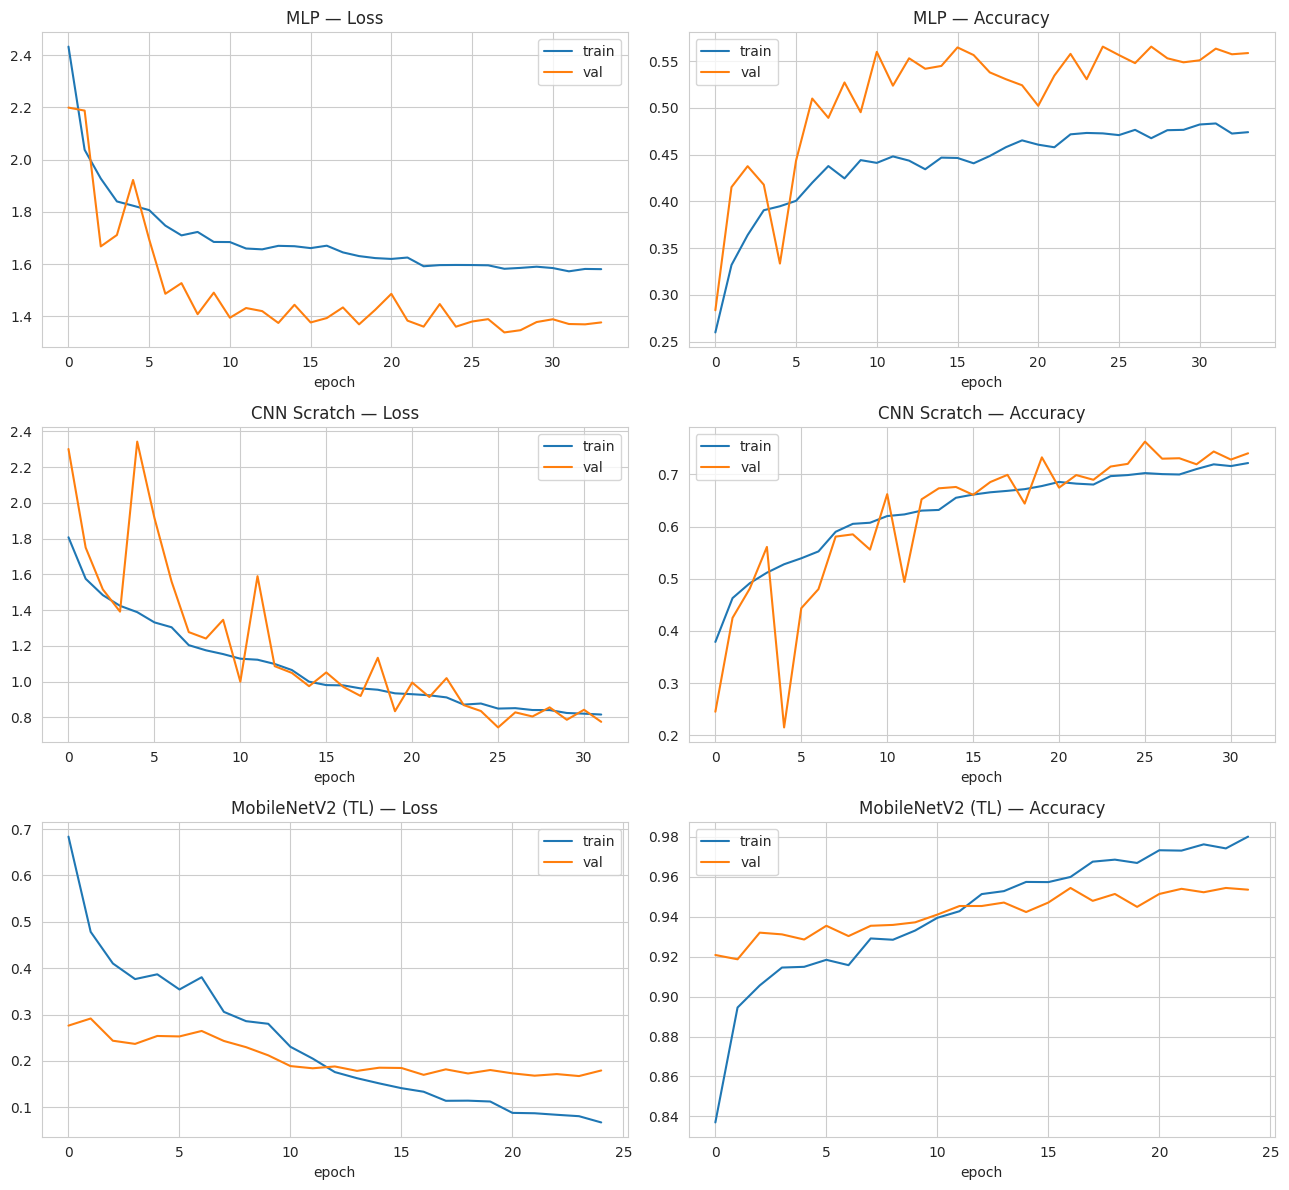

In [ ]:
fig, axes = plt.subplots(len(HIST), 2, figsize=(13, 4 * len(HIST)))
for i, (n, h) in enumerate(HIST.items()):
    axes[i, 0].plot(h["loss"], label="train"); axes[i, 0].plot(h["val_loss"], label="val")
    axes[i, 0].set_title(f"{n} — Loss"); axes[i, 0].set_xlabel("epoch"); axes[i, 0].legend()
    axes[i, 1].plot(h["accuracy"], label="train"); axes[i, 1].plot(h["val_accuracy"], label="val")
    axes[i, 1].set_title(f"{n} — Accuracy"); axes[i, 1].set_xlabel("epoch"); axes[i, 1].legend()
plt.tight_layout(); save_fig("05_kurva_training"); plt.show()

### 4.3 Confusion Matrix

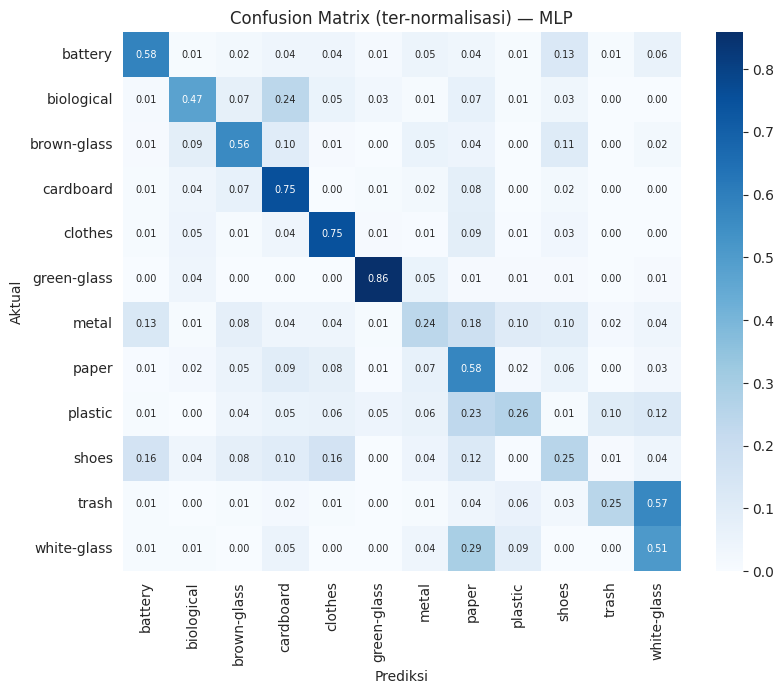

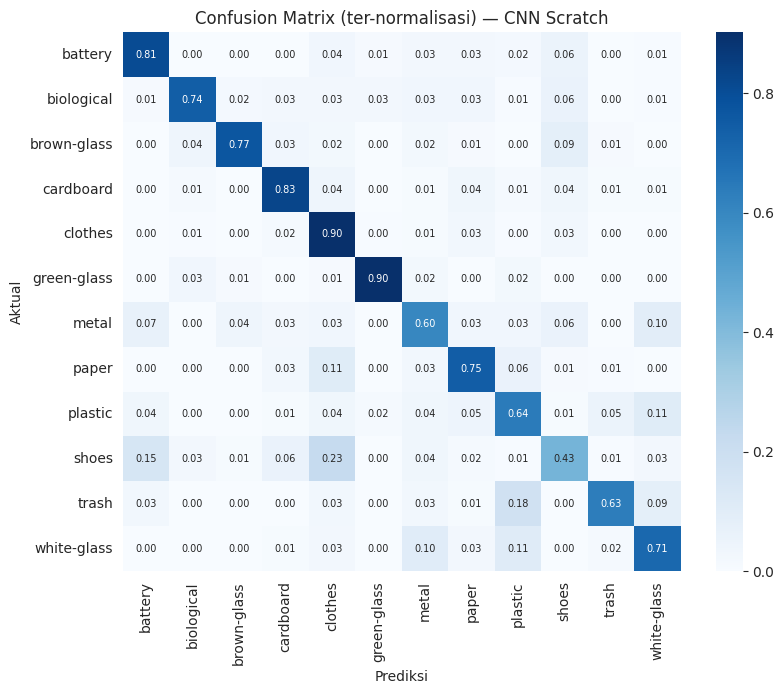

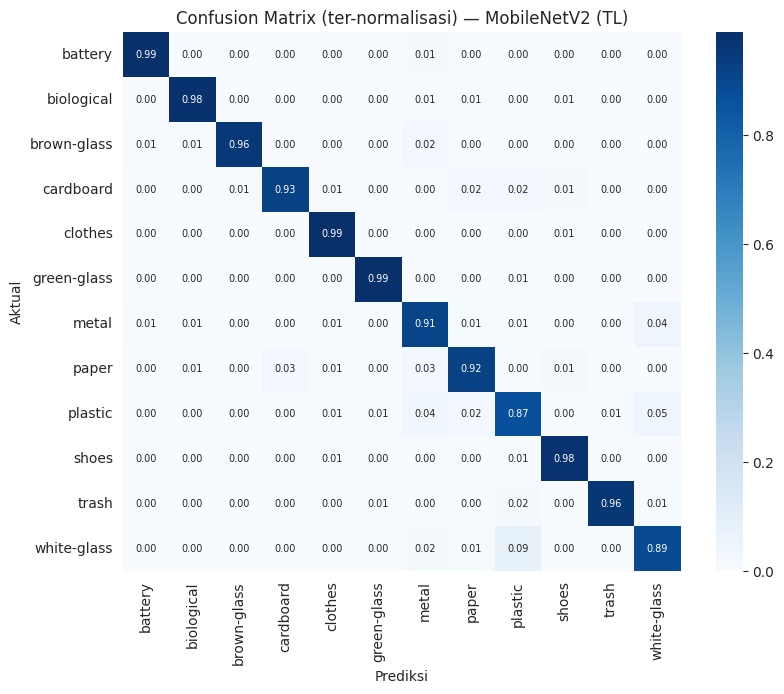

In [ ]:
for n in MODELS:
    cm = confusion_matrix(y_true, PRED[n], normalize="true")
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, annot_kws={"size": 7})
    plt.title(f"Confusion Matrix (ter-normalisasi) — {n}")
    plt.xlabel("Prediksi"); plt.ylabel("Aktual")
    save_fig("06_cm_" + n.split()[0].lower()); plt.show()

### 4.4 Classification Report dan F1 per Kelas

Classification report — MobileNetV2 (TL)
              precision    recall  f1-score   support

     battery     0.9859    0.9859    0.9859       142
  biological     0.9732    0.9797    0.9764       148
 brown-glass     0.9886    0.9560    0.9721        91
   cardboard     0.9688    0.9254    0.9466       134
     clothes     0.9925    0.9875    0.9900       799
 green-glass     0.9785    0.9891    0.9838        92
       metal     0.8607    0.9130    0.8861       115
       paper     0.9419    0.9241    0.9329       158
     plastic     0.8550    0.8682    0.8615       129
       shoes     0.9539    0.9764    0.9651       297
       trash     0.9804    0.9615    0.9709       104
 white-glass     0.8879    0.8879    0.8879       116

    accuracy                         0.9600      2325
   macro avg     0.9473    0.9462    0.9466      2325
weighted avg     0.9605    0.9600    0.9601      2325



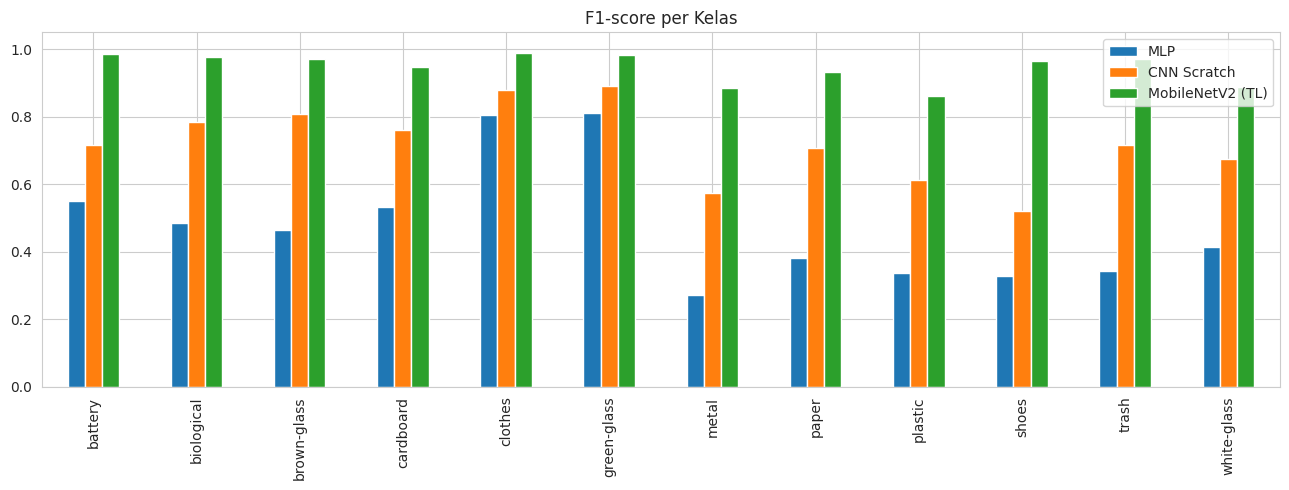

In [ ]:
print("Classification report —", BEST)
print(classification_report(y_true, PRED[BEST], target_names=CLASS_NAMES, digits=4))

f1_df = pd.DataFrame({n: f1_score(y_true, PRED[n], average=None) for n in MODELS}, index=CLASS_NAMES)
f1_df.plot(kind="bar", figsize=(13, 5), title="F1-score per Kelas")
plt.ylim(0, 1.05); plt.tight_layout(); save_fig("07_f1_per_kelas"); plt.show()

### 4.5 Analisis Kesalahan

,Kelas Aktual,Diprediksi Sebagai,Jumlah
0,white-glass,plastic,10
1,clothes,shoes,9
2,plastic,white-glass,6
3,metal,white-glass,5
4,plastic,metal,5
5,paper,cardboard,4
6,paper,metal,4
7,cardboard,paper,3
8,cardboard,plastic,3
9,plastic,paper,3


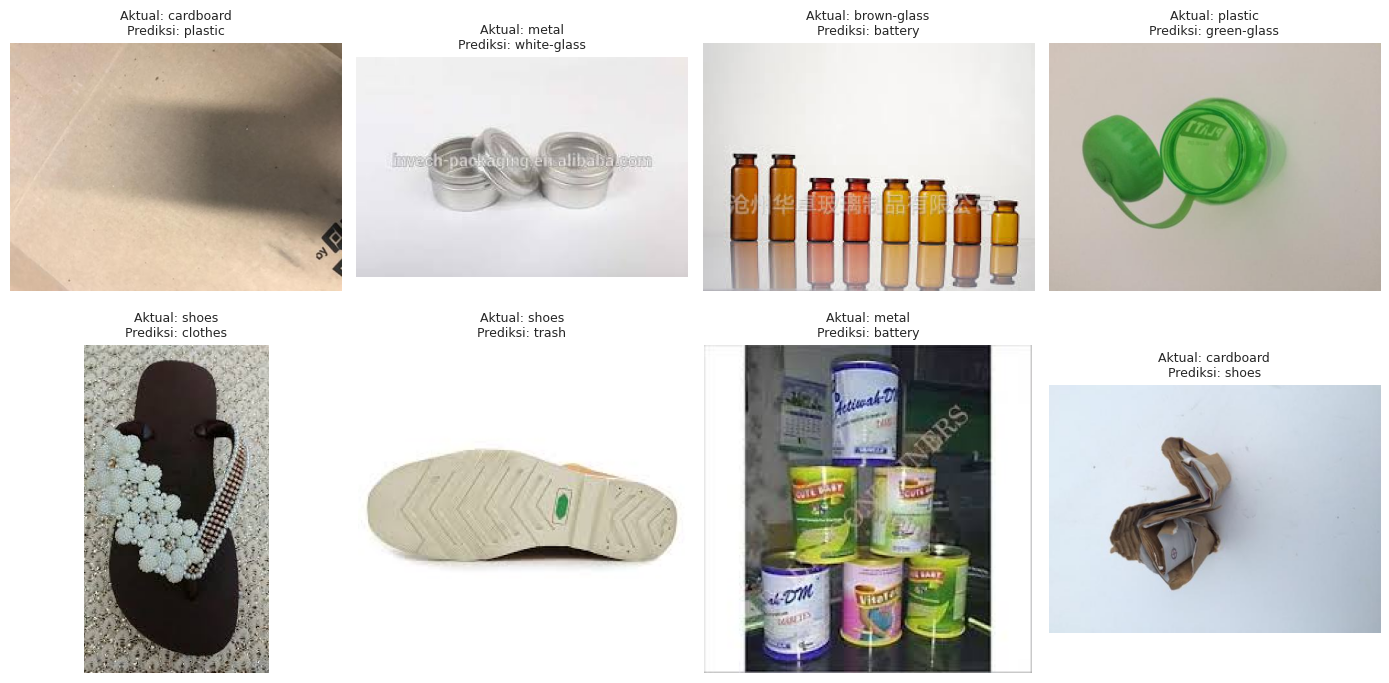

In [ ]:
cm = confusion_matrix(y_true, PRED[BEST])
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]))
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
pairs = sorted(pairs, key=lambda x: -x[2])[:10]
display(pd.DataFrame(pairs, columns=["Kelas Aktual", "Diprediksi Sebagai", "Jumlah"]))

wrong = np.where(PRED[BEST] != y_true)[0]
sel = np.random.RandomState(SEED).choice(wrong, size=min(8, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, k in zip(axes.ravel(), sel):
    row = test_df.iloc[k]
    with Image.open(row["path"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"Aktual: {CLASS_NAMES[row['label']]}\nPrediksi: {CLASS_NAMES[PRED[BEST][k]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); save_fig("08_contoh_salah_prediksi"); plt.show()

### 4.6 Fitur Unik 1 — Grad-CAM (Explainability)

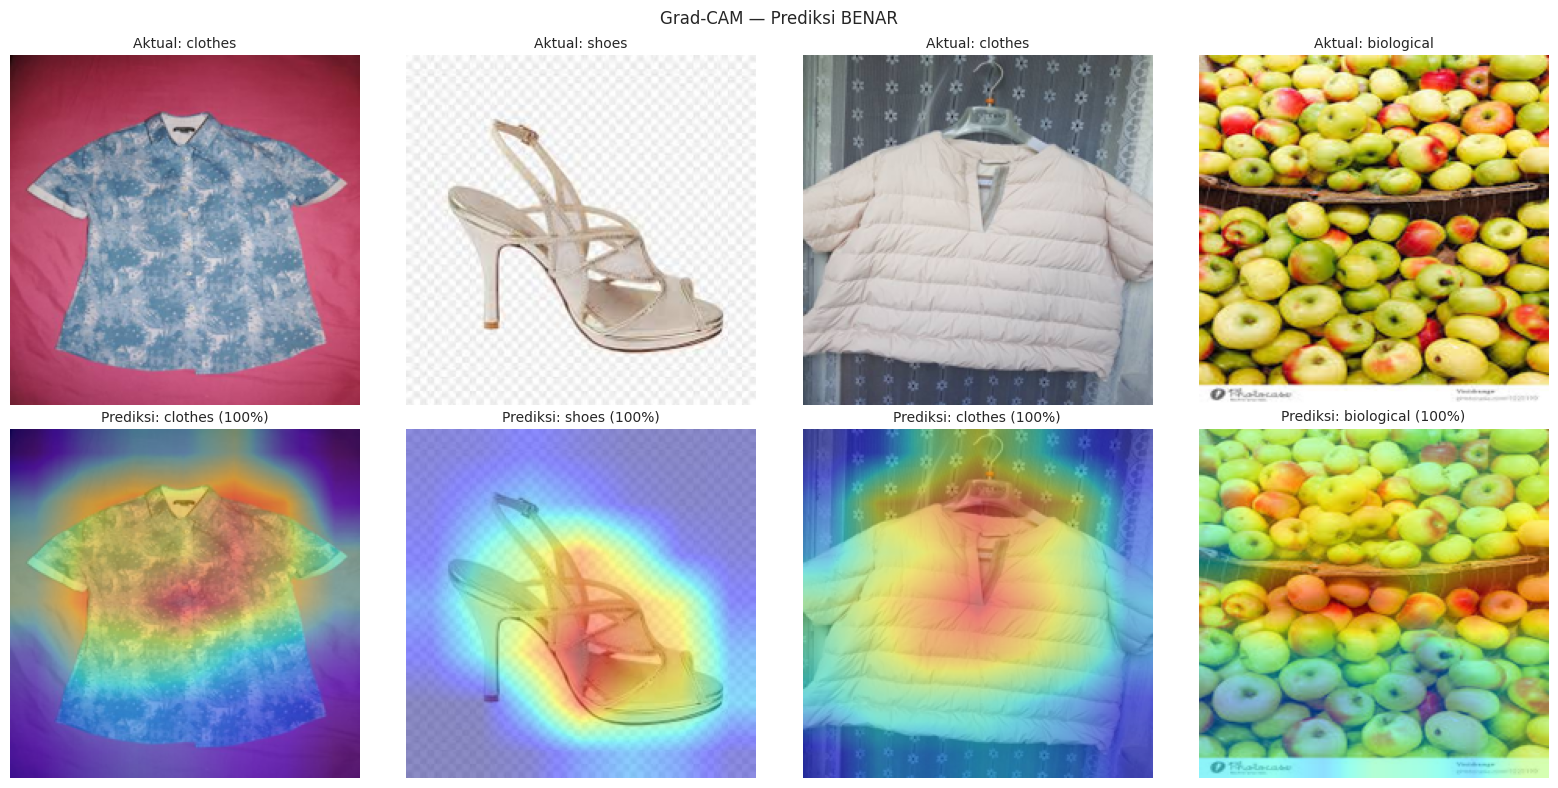

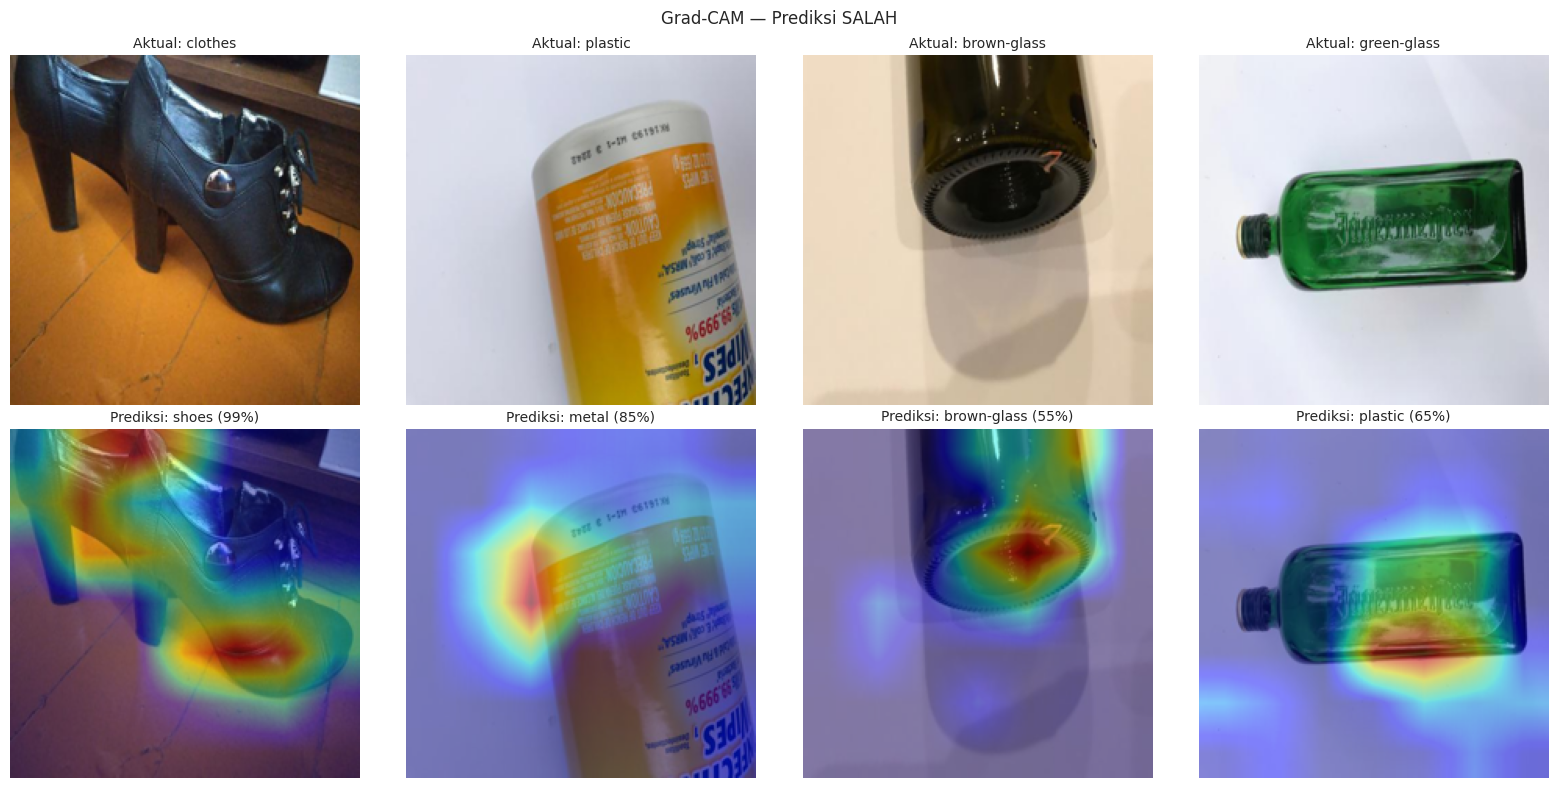

In [ ]:
base_tl = tl.get_layer("mobilenetv2_1.00_224")
gap_layer = [l for l in tl.layers if isinstance(l, layers.GlobalAveragePooling2D)][0]
head_layer = [l for l in tl.layers if isinstance(l, layers.Dense)][-1]

def load_arr(path):
    with Image.open(path) as im:
        return np.array(im.convert("RGB").resize(IMG_SIZE), dtype="float32")

def gradcam(arr, class_idx=None):
    x = tf.convert_to_tensor(arr[None], dtype=tf.float32) / 127.5 - 1.0
    with tf.GradientTape() as tape:
        tape.watch(x)
        fmap = base_tl(x, training=False)
        tape.watch(fmap)
        preds = head_layer(gap_layer(fmap))
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, fmap)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * fmap, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam, class_idx, preds[0].numpy()

def overlay(arr, cam, alpha=0.45):
    cam_img = np.array(Image.fromarray(np.uint8(255 * cam)).resize(IMG_SIZE, Image.BILINEAR)) / 255.0
    heat = plt.get_cmap("jet")(cam_img)[..., :3]
    return np.clip((1 - alpha) * arr / 255.0 + alpha * heat, 0, 1)

def show_cam(indices, title, fname):
    fig, axes = plt.subplots(2, len(indices), figsize=(4 * len(indices), 8))
    axes = np.atleast_2d(axes).reshape(2, -1)
    for j, k in enumerate(indices):
        row = test_df.iloc[k]
        arr = load_arr(row["path"])
        cam, ci, pr = gradcam(arr)
        axes[0, j].imshow(arr.astype("uint8")); axes[0, j].axis("off")
        axes[0, j].set_title(f"Aktual: {CLASS_NAMES[row['label']]}", fontsize=10)
        axes[1, j].imshow(overlay(arr, cam)); axes[1, j].axis("off")
        axes[1, j].set_title(f"Prediksi: {CLASS_NAMES[ci]} ({pr[ci]:.0%})", fontsize=10)
    fig.suptitle(title); plt.tight_layout(); save_fig(fname); plt.show()

pred_tl = PRED["MobileNetV2 (TL)"]
rs = np.random.RandomState(SEED)
right_idx = rs.choice(np.where(pred_tl == y_true)[0], size=4, replace=False)
wrong_all = np.where(pred_tl != y_true)[0]
wrong_idx = rs.choice(wrong_all, size=min(4, len(wrong_all)), replace=False)

show_cam(right_idx, "Grad-CAM — Prediksi BENAR", "10_gradcam_benar")
show_cam(wrong_idx, "Grad-CAM — Prediksi SALAH", "11_gradcam_salah")

# BAGIAN 5 — Teknologi, Deployment, dan Demo Program
Bagian: Aswan

### 5.1 Menyimpan Model Terbaik dan Daftar Kelas

In [ ]:
MODEL_PATH = "models/best_model.keras"
MODELS[BEST].save(MODEL_PATH)
with open("models/class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)
print("Model tersimpan:", MODEL_PATH, "| ukuran: %.1f MB" % (os.path.getsize(MODEL_PATH) / 1e6))

Model tersimpan: models/best_model.keras | ukuran: 21.9 MB


### 5.2 Verifikasi Model Hasil Simpan (reload dan uji inferensi)

In [ ]:
loaded = keras.models.load_model(MODEL_PATH, compile=False)
p_loaded = loaded.predict(test_ds, verbose=0).argmax(axis=1)
print("Kecocokan prediksi model asli vs hasil load: %.2f%%" % (100 * np.mean(p_loaded == PRED[BEST])))
print("Akurasi model hasil load pada test set    : %.4f" % accuracy_score(y_true, p_loaded))

Kecocokan prediksi model asli vs hasil load: 100.00%
Akurasi model hasil load pada test set    : 0.9600


### 5.3 Simulasi Inferensi (seperti pada aplikasi demo)

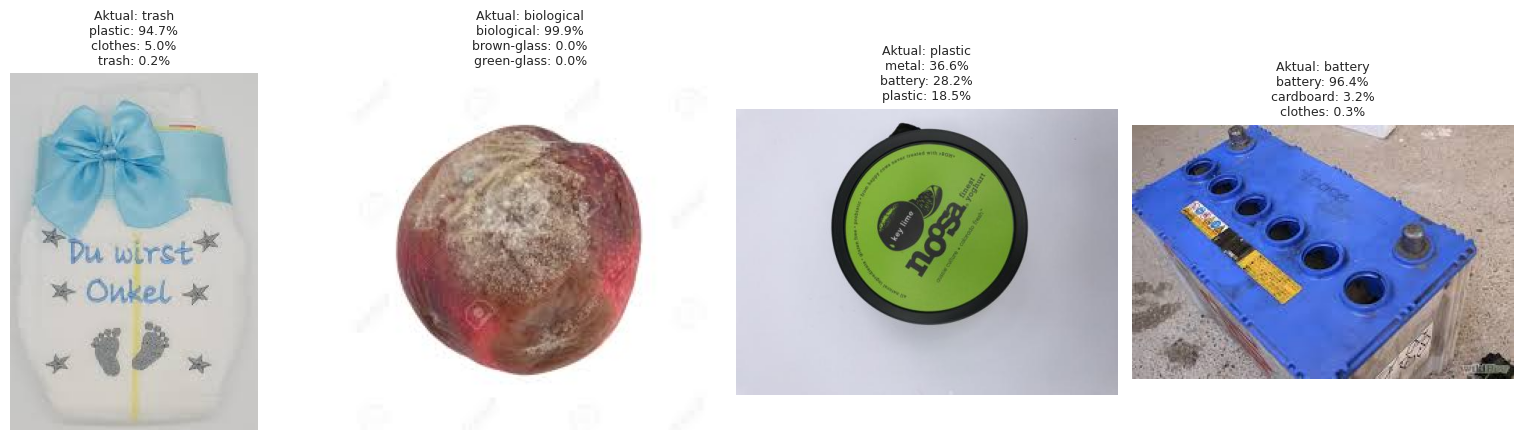

In [ ]:
def predict_image(path, topk=3):
    with Image.open(path) as im:
        arr = np.array(im.convert("RGB").resize(IMG_SIZE), dtype="float32")[None]
    probs = loaded.predict(arr, verbose=0)[0]
    idx = probs.argsort()[::-1][:topk]
    return [(CLASS_NAMES[i], float(probs[i])) for i in idx]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (_, row) in zip(axes, test_df.sample(4, random_state=SEED).iterrows()):
    res = predict_image(row["path"])
    with Image.open(row["path"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"Aktual: {row['class']}\n" + "\n".join(f"{c}: {p:.1%}" for c, p in res), fontsize=9)
    ax.axis("off")
plt.tight_layout(); save_fig("09_simulasi_inferensi"); plt.show()

### 5.4 Menjalankan Aplikasi Web (Streamlit)
Aplikasi ada di `app/streamlit_app.py`. Jalankan di komputer lokal: `pip install -r requirements.txt` lalu `streamlit run app/streamlit_app.py`.

### 5.5 Fitur Unik 2 — Confidence Threshold (Penolakan Input Tidak Meyakinkan / di Luar Domain)

Validation:


,threshold,coverage,akurasi_diterima,ditolak
0,0.00,1.0000,0.9544,0
1,0.30,1.0000,0.9544,0
2,0.40,0.9991,0.9548,2
3,0.50,0.9961,0.9559,9
4,0.60,0.9845,0.9615,36
5,0.70,0.9707,0.9663,68
6,0.80,0.9518,0.9724,112
7,0.90,0.9269,0.9833,170
8,0.95,0.8950,0.9880,244


Test:


,threshold,coverage,akurasi_diterima,ditolak
0,0.00,1.0000,0.9600,0
1,0.30,1.0000,0.9600,0
2,0.40,0.9991,0.9608,2
3,0.50,0.9901,0.9657,23
4,0.60,0.9781,0.9719,51
5,0.70,0.9596,0.9758,94
6,0.80,0.9441,0.9822,130
7,0.90,0.9204,0.9879,185
8,0.95,0.8968,0.9894,240


Threshold terpilih (berdasarkan data validation): 0.8


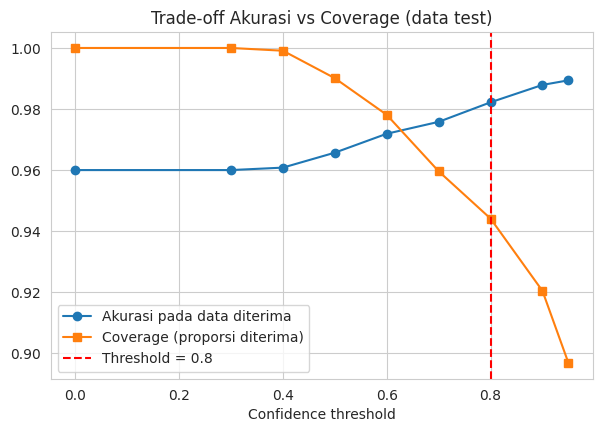

In [ ]:
GC = MODELS[BEST]
val_probs = GC.predict(val_ds, verbose=0)
test_probs = GC.predict(test_ds, verbose=0)
y_val = val_df["label"].values

def selective_table(probs, y, thresholds):
    conf, pred, rows = probs.max(axis=1), probs.argmax(axis=1), []
    for t in thresholds:
        keep = conf >= t
        acc = (pred[keep] == y[keep]).mean() if keep.any() else np.nan
        rows.append({"threshold": t, "coverage": round(float(keep.mean()), 4),
                     "akurasi_diterima": round(float(acc), 4), "ditolak": int((~keep).sum())})
    return pd.DataFrame(rows)

THRESHOLDS = [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
val_tab = selective_table(val_probs, y_val, THRESHOLDS)
test_tab = selective_table(test_probs, y_true, THRESHOLDS)
print("Validation:"); display(val_tab)
print("Test:"); display(test_tab)

ok = val_tab[(val_tab["akurasi_diterima"] >= 0.97) & (val_tab["coverage"] >= 0.85)]
THRESHOLD = float(ok["threshold"].iloc[0]) if len(ok) else 0.7
print("Threshold terpilih (berdasarkan data validation):", THRESHOLD)

plt.figure(figsize=(7, 4.5))
plt.plot(test_tab["threshold"], test_tab["akurasi_diterima"], marker="o", label="Akurasi pada data diterima")
plt.plot(test_tab["threshold"], test_tab["coverage"], marker="s", label="Coverage (proporsi diterima)")
plt.axvline(THRESHOLD, color="red", linestyle="--", label=f"Threshold = {THRESHOLD}")
plt.xlabel("Confidence threshold"); plt.legend(); plt.title("Trade-off Akurasi vs Coverage (data test)")
save_fig("12_threshold_tradeoff"); plt.show()

Rata-rata confidence prediksi benar: 0.9809
Rata-rata confidence prediksi salah : 0.7362
Prediksi SALAH yang berhasil ditolak: 58.06%
Prediksi BENAR yang ikut ditolak    : 3.41%
Input sintetis di luar domain (noise/warna polos/gradien): 200 citra
Ditolak oleh threshold: 40.50%


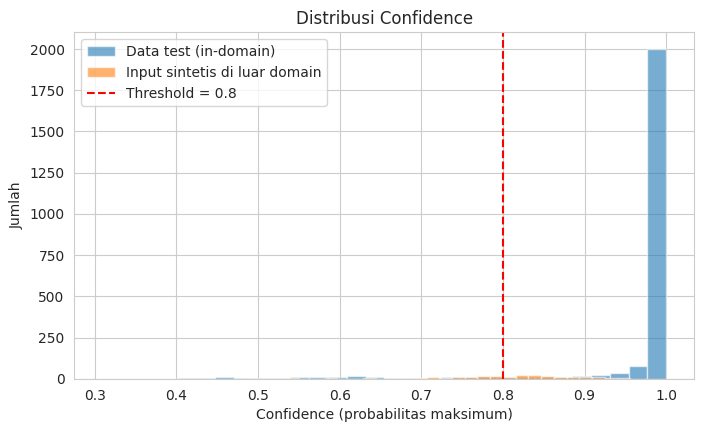

Tersimpan: models/config.json


In [ ]:
# Bukti dampak: confidence benar vs salah, dan uji input di luar domain (sintetis)
conf_test = test_probs.max(axis=1)
correct = test_probs.argmax(axis=1) == y_true
print("Rata-rata confidence prediksi benar: %.4f" % conf_test[correct].mean())
print("Rata-rata confidence prediksi salah : %.4f" % conf_test[~correct].mean())
print("Prediksi SALAH yang berhasil ditolak: %.2f%%" % (100 * (conf_test[~correct] < THRESHOLD).mean()))
print("Prediksi BENAR yang ikut ditolak    : %.2f%%" % (100 * (conf_test[correct] < THRESHOLD).mean()))

rng = np.random.RandomState(SEED)
ood = []
for _ in range(100):
    ood.append(rng.randint(0, 256, (*IMG_SIZE, 3)).astype("float32"))
for _ in range(50):
    ood.append(np.ones((*IMG_SIZE, 3), dtype="float32") * rng.randint(0, 256, (1, 1, 3)))
for _ in range(50):
    g = np.linspace(0, 255, IMG_SIZE[1], dtype="float32")[None, :, None] * np.ones((IMG_SIZE[0], 1, 3), dtype="float32")
    ood.append(g * rng.uniform(0.5, 1.0, (1, 1, 3)).astype("float32"))
ood = np.stack(ood)
ood_conf = GC.predict(ood, verbose=0).max(axis=1)
print("Input sintetis di luar domain (noise/warna polos/gradien): %d citra" % len(ood))
print("Ditolak oleh threshold: %.2f%%" % (100 * (ood_conf < THRESHOLD).mean()))

plt.figure(figsize=(8, 4.5))
plt.hist(conf_test, bins=30, alpha=0.6, label="Data test (in-domain)")
plt.hist(ood_conf, bins=30, alpha=0.6, label="Input sintetis di luar domain")
plt.axvline(THRESHOLD, color="red", linestyle="--", label=f"Threshold = {THRESHOLD}")
plt.xlabel("Confidence (probabilitas maksimum)"); plt.ylabel("Jumlah"); plt.legend()
plt.title("Distribusi Confidence"); save_fig("13_distribusi_confidence"); plt.show()

with open("models/config.json", "w") as f:
    json.dump({"threshold": THRESHOLD}, f)
print("Tersimpan: models/config.json")

# BAGIAN 6 — Ringkasan dan Artefak Dokumentasi
Bagian: Semua Anggota

In [ ]:
display(results)
print("Model terbaik:", BEST)

with open("assets/history.json", "w") as f:
    json.dump(HIST, f)
with open("assets/classification_report.txt", "w") as f:
    f.write(classification_report(y_true, PRED[BEST], target_names=CLASS_NAMES, digits=4))

print("\nBerkas yang dihasilkan:")
for folder in ("models", "assets"):
    for fn in sorted(os.listdir(folder)):
        print(f"  {folder}/{fn}")

,Parameter,Waktu Training (detik),Test Loss,Test Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,,,,
MLP,6429452,579.7,1.3597,0.5570,0.4905,0.5061,0.4769
CNN Scratch,458732,1634.0,0.7528,0.7548,0.7264,0.7262,0.7210
MobileNetV2 (TL),2273356,774.2,0.1359,0.9600,0.9473,0.9462,0.9466


Model terbaik: MobileNetV2 (TL)

Berkas yang dihasilkan:
  models/best_model.keras
  models/class_names.json
  models/config.json
  assets/01_distribusi_kelas.png
  assets/02_contoh_citra.png
  assets/03_distribusi_split.png
  assets/04_augmentasi.png
  assets/05_kurva_training.png
  assets/06_cm_cnn.png
  assets/06_cm_mlp.png
  assets/06_cm_mobilenetv2.png
  assets/07_f1_per_kelas.png
  assets/08_contoh_salah_prediksi.png
  assets/09_simulasi_inferensi.png
  assets/10_gradcam_benar.png
  assets/11_gradcam_salah.png
  assets/12_threshold_tradeoff.png
  assets/13_distribusi_confidence.png
  assets/arsitektur_cnn.png
  assets/arsitektur_mlp.png
  assets/arsitektur_mobilenetv2.png
  assets/classification_report.txt
  assets/eksperimen_hyperparameter.csv
  assets/hasil_perbandingan_model.csv
  assets/history.json


### 6.1 Informasi Lingkungan dan Versi Library (untuk bagian Teknologi)

In [ ]:
import sys, PIL, sklearn, matplotlib
gpus = tf.config.list_physical_devices("GPU")
gpu_name = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU") if gpus else "CPU"
env_info = {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__, "pillow": PIL.__version__,
            "gpu": gpu_name}
with open("assets/env_info.json", "w") as f:
    json.dump(env_info, f, indent=1)
display(pd.Series(env_info).to_frame("versi"))

,versi
python,3.13.16
tensorflow,2.21.0
keras,3.13.2
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
seaborn,0.13.2
pillow,11.3.0
gpu,Tesla T4


### 6.2 Kemas dan Unduh Folder models/ dan assets/ (zip)

In [ ]:
import zipfile
ZIP_NAME = "hasil_proyek.zip"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ("models", "assets"):
        for fn in sorted(os.listdir(folder)):
            z.write(os.path.join(folder, fn))
print("Dibuat:", ZIP_NAME, "| ukuran: %.1f MB" % (os.path.getsize(ZIP_NAME) / 1e6))
try:
    from google.colab import files
    files.download(ZIP_NAME)
except ImportError:
    print("Bukan Google Colab: unduh hasil_proyek.zip dari panel Output/Files.")

Dibuat: hasil_proyek.zip | ukuran: 30.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>